<a href="https://colab.research.google.com/github/mehnazpa/WildHeartz/blob/main/data_preprocess.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Employee.csv")


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Data Types:")
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())

Rows: 4653
Columns: 9
Data Types:
Education                    object
JoiningYear                   int64
City                         object
PaymentTier                   int64
Age                           int64
Gender                       object
EverBenched                  object
ExperienceInCurrentDomain     int64
LeaveOrNot                    int64
dtype: object
Missing values:
Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64


In [ ]:
df.head()


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [ ]:
df.tail()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0
4649,Masters,2013,Pune,2,37,Male,No,2,1
4650,Masters,2018,New Delhi,3,27,Male,No,5,1
4651,Bachelors,2012,Bangalore,3,30,Male,Yes,2,0
4652,Bachelors,2015,Bangalore,3,33,Male,Yes,4,0


In [ ]:
df.sample()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
4559,Bachelors,2016,Bangalore,3,40,Male,No,3,0


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64


In [ ]:
#mean
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

In [ ]:
#mode
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
#deletion
df = df.dropna()

In [ ]:
#median
df["Age"] = df["Age"].fillna(df["Age"].median())

In [ ]:
#interpolation
df = df.interpolate()

/tmp/ipykernel_19503/221517839.py:1: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df = df.interpolate()


In [ ]:
print(df.isnull().sum())

Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64


In [ ]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())
print(df[df.duplicated()])

Number of duplicate rows: 1889
      Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
111   Bachelors         2017       Pune            2   27  Female          No   
130   Bachelors         2017  Bangalore            3   26  Female          No   
138   Bachelors         2017  New Delhi            3   28    Male          No   
160   Bachelors         2014  Bangalore            3   28  Female          No   
167   Bachelors         2014  Bangalore            3   25    Male          No   
...         ...          ...        ...          ...  ...     ...         ...   
4640  Bachelors         2015  Bangalore            3   35    Male          No   
4642  Bachelors         2012  Bangalore            3   36  Female          No   
4646  Bachelors         2013  Bangalore            3   25  Female          No   
4648  Bachelors         2013  Bangalore            3   26  Female          No   
4652  Bachelors         2015  Bangalore            3   33    Male         Yes 

In [ ]:
df = df.drop_duplicates()
print("Number of duplicate rows after removal:", df.duplicated().sum())

Number of duplicate rows after removal: 0


Outliers:
Empty DataFrame
Columns: [Education, JoiningYear, City, PaymentTier, Age, Gender, EverBenched, ExperienceInCurrentDomain, LeaveOrNot]
Index: []


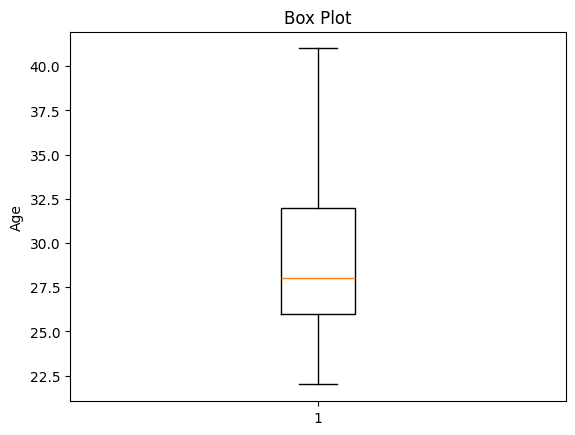

In [ ]:
import matplotlib.pyplot as plt

column = "Age"

Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

print("Outliers:")
print(outliers)

plt.boxplot(df[column])
plt.title("Box Plot")
plt.ylabel(column)
plt.show()

Empty DataFrame
Columns: [Education, JoiningYear, City, PaymentTier, Age, Gender, EverBenched, ExperienceInCurrentDomain, LeaveOrNot, Z_score]
Index: []


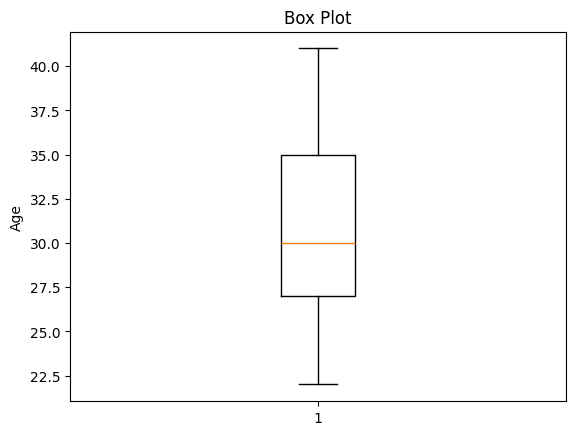

In [ ]:
from scipy.stats import zscore

column = "Age"

df["Z_score"] = zscore(df[column])

outliers = df[abs(df["Z_score"]) > 3]

print(outliers)

plt.boxplot(df[column])
plt.title("Box Plot")
plt.ylabel(column)
plt.show()

In [ ]:
column = "Age"
Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

print(df)

      Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
0     Bachelors         2017  Bangalore            3   34    Male          No   
1     Bachelors         2013       Pune            1   28  Female          No   
2     Bachelors         2014  New Delhi            3   38  Female          No   
3       Masters         2016  Bangalore            3   27    Male          No   
4       Masters         2017       Pune            3   24    Male         Yes   
...         ...          ...        ...          ...  ...     ...         ...   
4648  Bachelors         2013  Bangalore            3   26  Female          No   
4649    Masters         2013       Pune            2   37    Male          No   
4650    Masters         2018  New Delhi            3   27    Male          No   
4651  Bachelors         2012  Bangalore            3   30    Male         Yes   
4652  Bachelors         2015  Bangalore            3   33    Male         Yes   

      ExperienceInCurrentDo

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["City"] = le.fit_transform(df["City"])

print(df.head())

   Education  JoiningYear  City  PaymentTier  Age  Gender EverBenched  \
0  Bachelors         2017     0            3   34    Male          No   
1  Bachelors         2013     2            1   28  Female          No   
2  Bachelors         2014     1            3   38  Female          No   
3    Masters         2016     0            3   27    Male          No   
4    Masters         2017     2            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot  
0                          0           0  
1                          3           1  
2                          2           0  
3                          5           1  
4                          2           1  


In [ ]:
df = pd.get_dummies(df, columns=["City"])

print(df.head())

   Education  JoiningYear  PaymentTier  Age  Gender EverBenched  \
0  Bachelors         2017            3   34    Male          No   
1  Bachelors         2013            1   28  Female          No   
2  Bachelors         2014            3   38  Female          No   
3    Masters         2016            3   27    Male          No   
4    Masters         2017            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot   Z_score  City_0  City_1  City_2  
0                          0           0  0.596528    True   False   False  
1                          3           1 -0.578112   False   False    True  
2                          2           0  1.379621   False    True   False  
3                          5           1 -0.773885    True   False   False  
4                          2           1 -1.361206   False   False    True  


In [ ]:
from sklearn.preprocessing import MinMaxScaler

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

scaler = MinMaxScaler()

df[num_cols] = scaler.fit_transform(df[num_cols])

print(df.head())

   Education  JoiningYear       City  PaymentTier       Age  Gender  \
0  Bachelors     0.833333  Bangalore          1.0  0.631579    Male   
1  Bachelors     0.166667       Pune          0.0  0.315789  Female   
2  Bachelors     0.333333  New Delhi          1.0  0.842105  Female   
3    Masters     0.666667  Bangalore          1.0  0.263158    Male   
4    Masters     0.833333       Pune          1.0  0.105263    Male   

  EverBenched  ExperienceInCurrentDomain  LeaveOrNot  
0          No                   0.000000         0.0  
1          No                   0.428571         1.0  
2          No                   0.285714         0.0  
3          No                   0.714286         1.0  
4         Yes                   0.285714         1.0  


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df["Age_Standardized"] = scaler.fit_transform(df[["Age"]])

print(df.head())

   Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
0  Bachelors         2017  Bangalore            3   34    Male          No   
1  Bachelors         2013       Pune            1   28  Female          No   
2  Bachelors         2014  New Delhi            3   38  Female          No   
3    Masters         2016  Bangalore            3   27    Male          No   
4    Masters         2017       Pune            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot  Age_Standardized  
0                          0           0          0.954645  
1                          3           1         -0.288732  
2                          2           0          1.783563  
3                          5           1         -0.495961  
4                          2           1         -1.117650  


                           JoiningYear  PaymentTier       Age  \
JoiningYear                   1.000000    -0.053823  0.024445   
PaymentTier                  -0.053823     1.000000  0.067514   
Age                           0.024445     0.067514  1.000000   
ExperienceInCurrentDomain    -0.031228    -0.004602 -0.053276   
LeaveOrNot                    0.150650    -0.119891 -0.114943   
Z_score                       0.024445     0.067514  1.000000   
City_0                       -0.075685     0.193877  0.101496   
City_1                        0.093514    -0.038143 -0.089253   
City_2                       -0.010763    -0.173157 -0.021596   
Age_Standardized              0.024445     0.067514  1.000000   

                           ExperienceInCurrentDomain  LeaveOrNot   Z_score  \
JoiningYear                                -0.031228    0.150650  0.024445   
PaymentTier                                -0.004602   -0.119891  0.067514   
Age                                        -0.0532

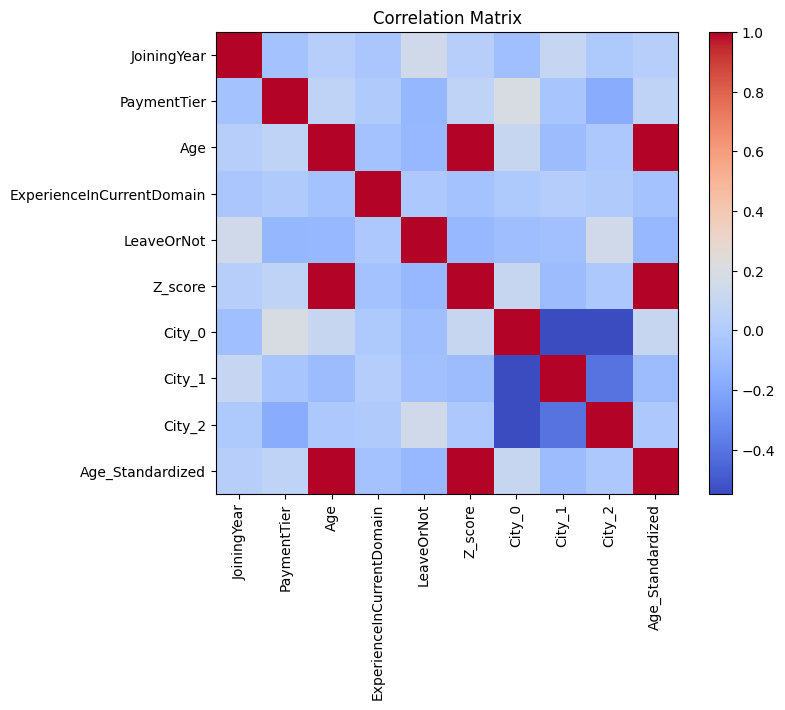

In [ ]:
import matplotlib.pyplot as plt

# Correlation matrix
correlation = df.corr(numeric_only=True)

print(correlation)

# Plot
plt.figure(figsize=(8,6))
plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Matrix")
plt.show()

Correlation Matrix:
                           JoiningYear  PaymentTier       Age  \
JoiningYear                   1.000000    -0.053823  0.024445   
PaymentTier                  -0.053823     1.000000  0.067514   
Age                           0.024445     0.067514  1.000000   
ExperienceInCurrentDomain    -0.031228    -0.004602 -0.053276   
LeaveOrNot                    0.150650    -0.119891 -0.114943   
Z_score                       0.024445     0.067514  1.000000   
City_0                       -0.075685     0.193877  0.101496   
City_1                        0.093514    -0.038143 -0.089253   
City_2                       -0.010763    -0.173157 -0.021596   
Age_Standardized              0.024445     0.067514  1.000000   

                           ExperienceInCurrentDomain  LeaveOrNot   Z_score  \
JoiningYear                                -0.031228    0.150650  0.024445   
PaymentTier                                -0.004602   -0.119891  0.067514   
Age                           

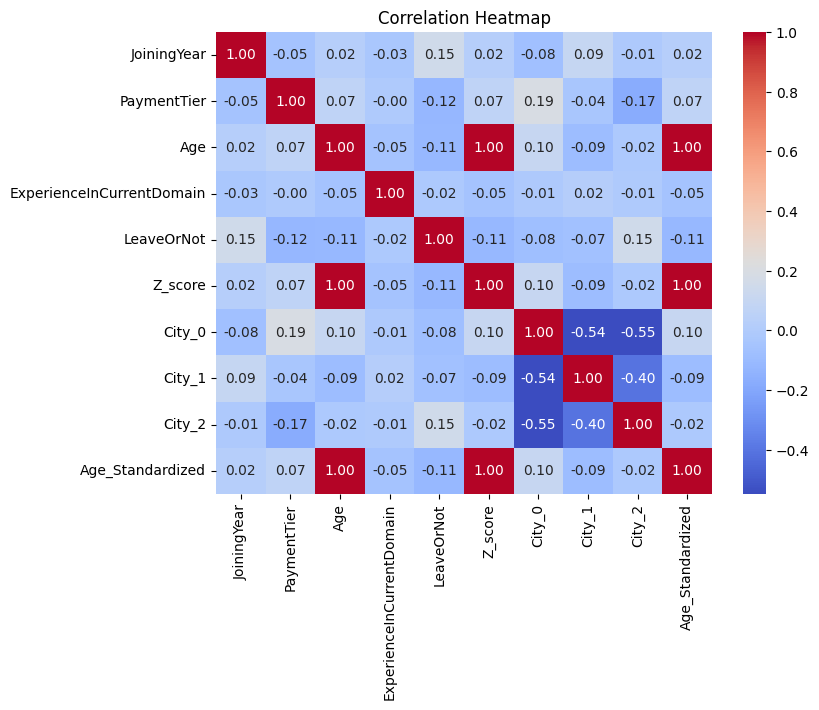

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation Matrix
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
print(correlation)

# Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df["YearsInCompany"] = 2026 - df["JoiningYear"]

print(df.head())

   Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
0  Bachelors         2017  Bangalore            3   34    Male          No   
1  Bachelors         2013       Pune            1   28  Female          No   
2  Bachelors         2014  New Delhi            3   38  Female          No   
3    Masters         2016  Bangalore            3   27    Male          No   
4    Masters         2017       Pune            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot  YearsInCompany  
0                          0           0               9  
1                          3           1              13  
2                          2           0              12  
3                          5           1              10  
4                          2           1               9  


In [ ]:
df["JoiningYear"] = pd.to_datetime(df["JoiningYear"], format="%Y")

print(df.head(5))

   Education JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
0  Bachelors  2017-01-01  Bangalore            3   34    Male          No   
1  Bachelors  2013-01-01       Pune            1   28  Female          No   
2  Bachelors  2014-01-01  New Delhi            3   38  Female          No   
3    Masters  2016-01-01  Bangalore            3   27    Male          No   
4    Masters  2017-01-01       Pune            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot  Age_Standardized  
0                          0           0          0.954645  
1                          3           1         -0.288732  
2                          2           0          1.783563  
3                          5           1         -0.495961  
4                          2           1         -1.117650  


In [ ]:
# Remove extra spaces
df["City"] = df["City"].str.strip()
df["Education"] = df["Education"].str.strip()

# Standardize text
df["City"] = df["City"].str.title()
df["Gender"] = df["Gender"].str.capitalize()

# Remove unrealistic ages
df = df[(df["Age"] >= 18) & (df["Age"] <= 60)]

# Check cleaned values
print(df["Gender"].unique())
print(df["City"].unique())

['Male' 'Female']
['Bangalore' 'Pune' 'New Delhi']


In [ ]:
from sklearn.model_selection import train_test_split

# Features
X = df.drop("LeaveOrNot", axis=1)

# Target
y = df["LeaveOrNot"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3722, 9)
Testing data: (931, 9)


In [ ]:
print(df["LeaveOrNot"].value_counts())

LeaveOrNot
0    3053
1    1600
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

le = LabelEncoder()

for col in df_encoded.select_dtypes(include='object').columns:
    df_encoded[col] = le.fit_transform(df_encoded[col])

In [ ]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop("LeaveOrNot", axis=1)
y = df_encoded["LeaveOrNot"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_balanced, y_balanced = smote.fit_resample(X_train, y_train)

print(y_balanced.value_counts())

LeaveOrNot
1    2443
0    2443
Name: count, dtype: int64


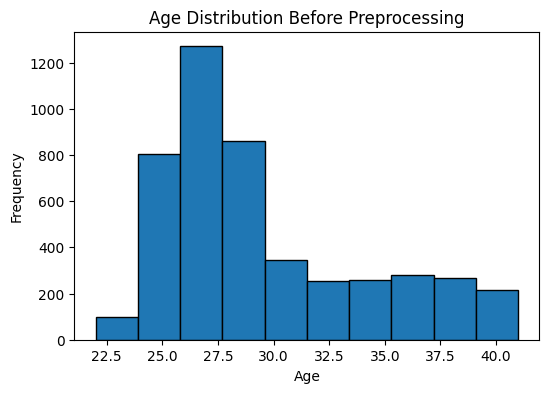

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.hist(df["Age"], bins=10, edgecolor="black")
plt.title("Age Distribution Before Preprocessing")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

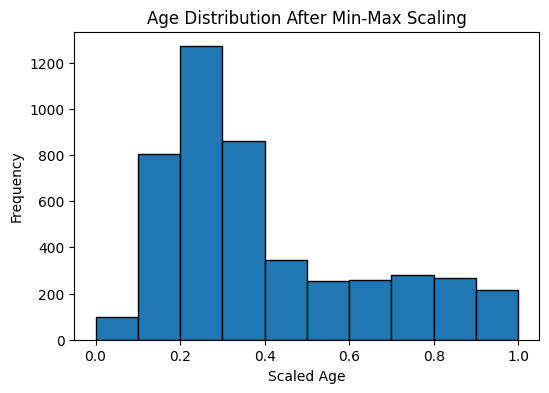

In [ ]:
from sklearn.preprocessing import MinMaxScaler

df_scaled = df.copy()

scaler = MinMaxScaler()
df_scaled["Age"] = scaler.fit_transform(df[["Age"]])

plt.figure(figsize=(6,4))
plt.hist(df_scaled["Age"], bins=10, edgecolor="black")
plt.title("Age Distribution After Min-Max Scaling")
plt.xlabel("Scaled Age")
plt.ylabel("Frequency")
plt.show()

In [ ]:
df.to_csv("Employee_Preprocessed.csv", index=False)

print("Dataset saved successfully.")

Dataset saved successfully.


In [ ]:
from google.colab import files

files.download("Employee_Preprocessed.csv")

FileNotFoundError: Cannot find file: Employee_Preprocessed.csv